# WEATHER PREDICTION

In [61]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import missingno as ms 
from statsmodels.tsa.stattools import adfuller
import plotly.graph_objects as go

%matplotlib inline
print(" Done setup" )

 Done setup


In [62]:
df = pd.read_csv("seattle-weather.csv")
df.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


## data discriptions

### shape of the data

In [63]:
df.shape

(1461, 6)

### descibe the data

In [64]:
df.describe(include = 'all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,1461,1461,2012-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
precipitation,1461.0,NaN,NaN,NaN,3.029432,6.680194,0.0,0.0,0.0,2.8,55.9
temp_max,1461.0,NaN,NaN,NaN,16.439083,7.349758,-1.6,10.6,15.6,22.2,35.6
temp_min,1461.0,NaN,NaN,NaN,8.234771,5.023004,-7.1,4.4,8.3,12.2,18.3
wind,1461.0,NaN,NaN,NaN,3.241136,1.437825,0.4,2.2,3.0,4.0,9.5
weather,1461,5,rain,641,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### information of data

In [65]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           1461 non-null   str    
 1   precipitation  1461 non-null   float64
 2   temp_max       1461 non-null   float64
 3   temp_min       1461 non-null   float64
 4   wind           1461 non-null   float64
 5   weather        1461 non-null   str    
dtypes: float64(4), str(2)
memory usage: 88.0 KB


### null values
- informarin, change date column into datetime from str.

In [66]:
df.isna().sum()

date             0
precipitation    0
temp_max         0
temp_min         0
wind             0
weather          0
dtype: int64

<Axes: >

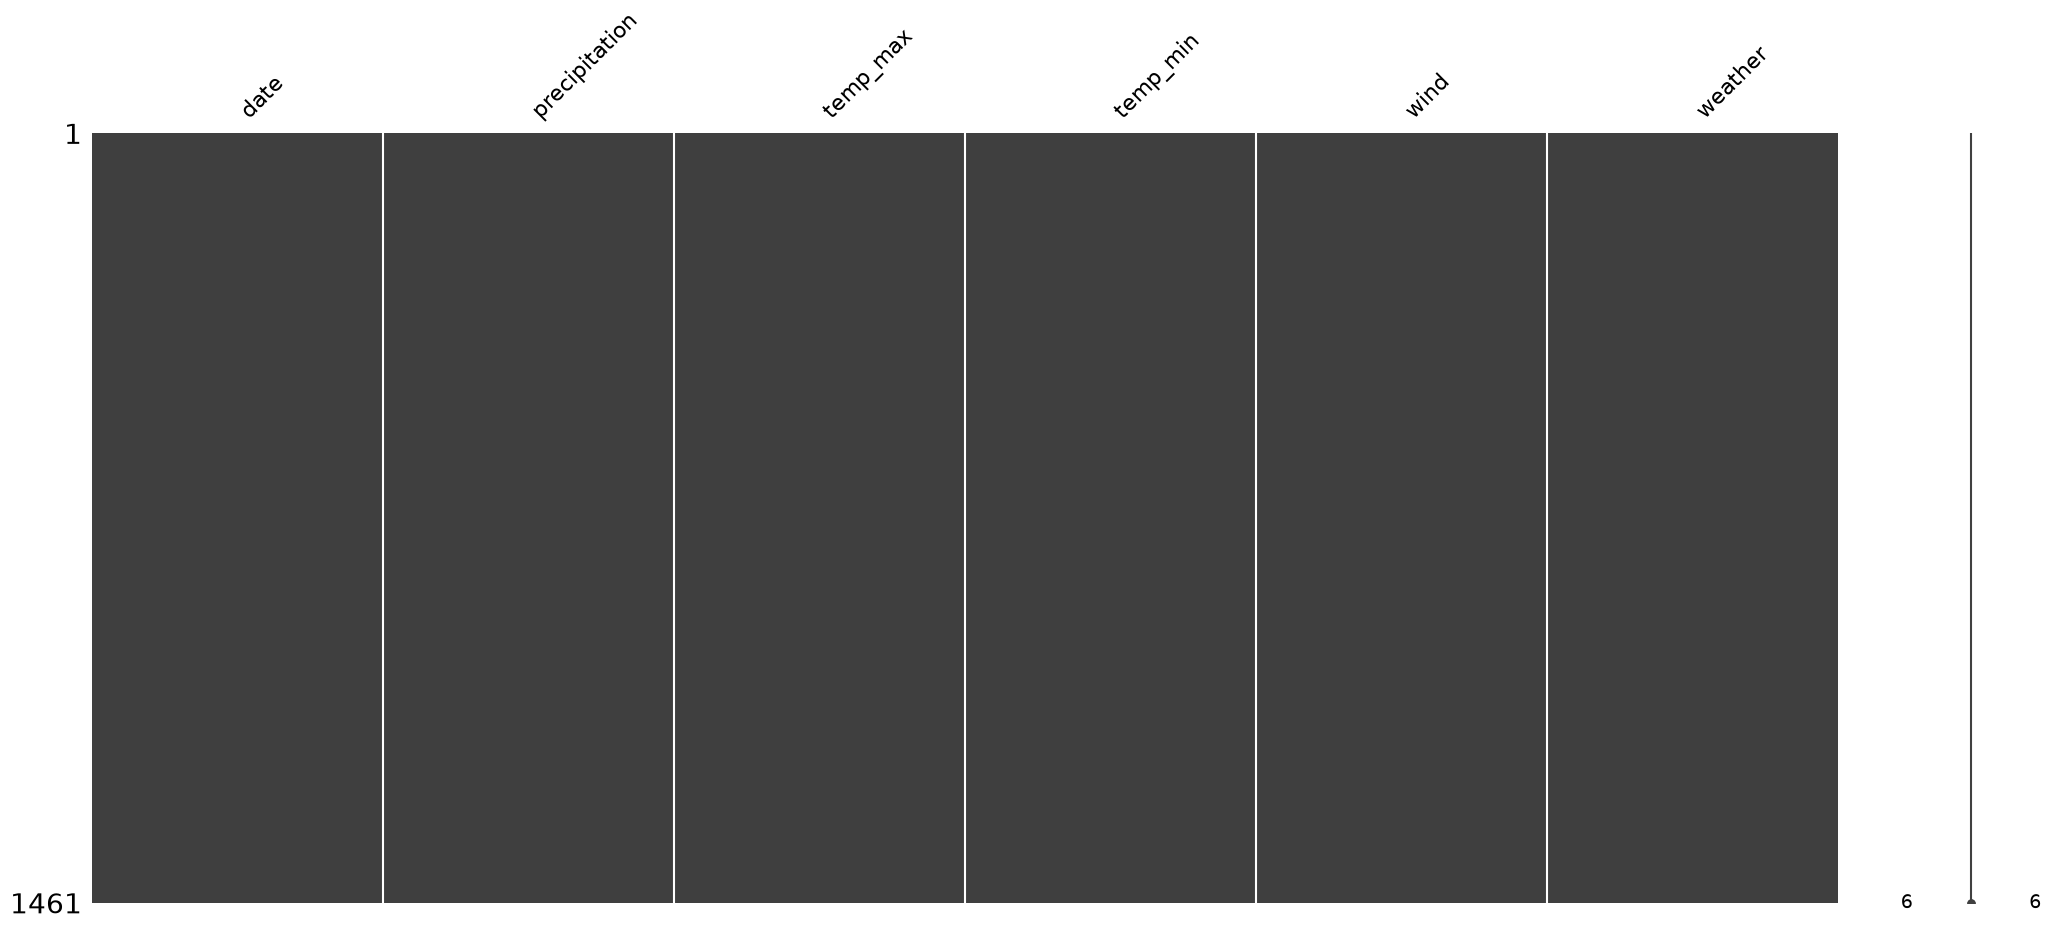

In [67]:
ms.matrix(df)

## Time-Series Analysis

### Analysing seasonality, trend, and autoregression 

### converted date column into date-time frame

In [68]:

## year wise
# conveting date column into datetime
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

#defined function 
def to_datetime(X):
    return pd.DataFrame(pd.to_datetime(X.iloc[:,0]))

trf = ColumnTransformer([
    ('datetime-data',FunctionTransformer(to_datetime), [0])
], remainder='passthrough')

#fit transfrom
transformed_data = trf.fit_transform(df)
data = pd.DataFrame(transformed_data, columns=df.columns)
data.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


### analysing precipitation, temp_max, temp_min and wind over the year in seattle



#### for max_temperature checking for stationarity

In [69]:
import plotly.graph_objects as go
import pandas as pd

# 1. Ensure the date column is explicitly parsed as datetime and set as index
data['date'] = pd.to_datetime(data['date'])
data = data.set_index('date')

# 2. Make the series stationary by applying first-order differencing
stationary_temp = data['temp_max'].diff().dropna()

# 3. Calculate rolling statistics on the stationary series (30-day window)
window_size = 30
rolling_mean_stat = stationary_temp.rolling(window=window_size).mean()
rolling_std_stat = stationary_temp.rolling(window=window_size).std()

# 4. Create interactive Plotly figure
fig = go.Figure()

# - Raw Differenced Data
fig.add_trace(go.Scatter(
    x=stationary_temp.index, y=stationary_temp, 
    name='Differenced Max Temp (Stationary)', 
    line=dict(color='lightblue', width=1), opacity=0.6
))

# - Rolling Mean
fig.add_trace(go.Scatter(
    x=rolling_mean_stat.index, y=rolling_mean_stat, 
    name='30-Day Rolling Mean (Flat)', 
    line=dict(color='red', width=2)
))

# - Rolling Standard Deviation
fig.add_trace(go.Scatter(
    x=rolling_std_stat.index, y=rolling_std_stat, 
    name='30-Day Rolling Std (Stable)', 
    line=dict(color='green', width=1.5), yaxis='y2'
))

# Layout configuration
fig.update_layout(
    title_text="<b>Stationary Series: Flat Rolling Mean & Stable Variance</b>",
    xaxis_title="Date",
    yaxis_title="Differenced Value",
    yaxis2=dict(
        title="Rolling Std Dev",
        overlaying='y',
        side='right',
        showgrid=False
    ),
    hovermode="x unified",
    height=500
)

fig.show()

In [70]:
# Group your stationary series by year and check mean & std


result = adfuller(data['temp_max'].dropna())

print(f"ADF Test Statistic: {result[0]:.4f}")
print(f"p-value: {result[1]:.4e}")
print("Critical Values:")
for key, value in result[4].items():
    print(f"   {key}: {value:.4f}")

ADF Test Statistic: -2.4292
p-value: 1.3366e-01
Critical Values:
   1%: -3.4349
   5%: -2.8635
   10%: -2.5678


- our critical value is 5%, adf test shows stats greater than 5%
- N not -> 'the max temperature is non-stationarity, meaning std, mean, variance, nothing remained constant over the year
- N alternate -> ' the max temp is stationariy  / no non-statinariy

##### original case
-> we fail to reject N0 meaning we are somehow accepting the data is non-stationary. Since, p_value > 5%

### achieving stationarity 
-> diff

In [71]:
import plotly.graph_objects as go
import pandas as pd

# 1. Ensure the date column is explicitly parsed as datetime and set as index

# 2. Make the series stationary by applying first-order differencing
stationary_temp = data['temp_max'].diff().dropna()

# 3. Calculate rolling statistics on the stationary series (30-day window)
window_size = 30
rolling_mean_stat = stationary_temp.rolling(window=window_size).mean()
rolling_std_stat = stationary_temp.rolling(window=window_size).std()

# 4. Create interactive Plotly figure
fig = go.Figure()

# - Raw Differenced Data
fig.add_trace(go.Scatter(
    x=stationary_temp.index, y=stationary_temp, 
    name='Differenced Max Temp (Stationary)', 
    line=dict(color='lightblue', width=1), opacity=0.6
))

# - Rolling Mean
fig.add_trace(go.Scatter(
    x=rolling_mean_stat.index, y=rolling_mean_stat, 
    name='30-Day Rolling Mean (Flat)', 
    line=dict(color='red', width=2)
))

# - Rolling Standard Deviation
fig.add_trace(go.Scatter(
    x=rolling_std_stat.index, y=rolling_std_stat, 
    name='30-Day Rolling Std (Stable)', 
    line=dict(color='green', width=1.5), yaxis='y2'
))

# Layout configuration
fig.update_layout(
    title_text="<b>Stationary Series: Flat Rolling Mean & Stable Variance</b>",
    xaxis_title="Date",
    yaxis_title="Differenced Value",
    yaxis2=dict(
        title="Rolling Std Dev",
        overlaying='y',
        side='right',
        showgrid=False
    ),
    hovermode="x unified",
    height=500
)

fig.show()

In [72]:
result = adfuller(stationary_temp.dropna())

print(f"ADF Test Statistic: {result[0]:.4f}")
print(f"p-value: {result[1]:.4e}")
print("Critical Values:")
for key, value in result[4].items():
    print(f"   {key}: {value:.4f}")

ADF Test Statistic: -15.6132
p-value: 1.7694e-28
Critical Values:
   1%: -3.4349
   5%: -2.8635
   10%: -2.5678


#### interpreting diff
-> since, first we have removed the first nan value fro the data. 
-> we are rejecting N0

### min temp

In [73]:
# adf for min temp 
min_result = adfuller(data['temp_min'].dropna()) 
print(f" ADF test statictic: {min_result[0]:.4f}")
print(f"p-values: {min_result[1]:.4e}")
print(f"Critical values:")
for key, value in min_result[4].items():
    print(f" {key} : {value:.4f}")               

 ADF test statictic: -2.6056
p-values: 9.1841e-02
Critical values:
 1% : -3.4349
 5% : -2.8635
 10% : -2.5678


In [74]:

# Ensure datetime index and sort
data.index = pd.to_datetime(data.index)
data = data.sort_index()

# Calculate rolling statistics (e.g., a 30-day window)
window_size = 30
rolling_mean = data['temp_min'].rolling(window=window_size).mean()
rolling_std = data['temp_min'].rolling(window=window_size).std()

# Create interactive Plotly figure
fig = go.Figure()

# 1. Raw Data
fig.add_trace(go.Scatter(
    x=data.index, y=data['temp_min'], 
    name='Original Min Temp', 
    line=dict(color='lightblue', width=1), opacity=0.7
))

# 2. Rolling Mean
fig.add_trace(go.Scatter(
    x=data.index, y=rolling_mean, 
    name=f'{window_size}-Day Rolling Mean', 
    line=dict(color='red', width=2)
))

# 3. Rolling Standard Deviation
fig.add_trace(go.Scatter(
    x=data.index, y=rolling_std, 
    name=f'{window_size}-Day Rolling Std', 
    line=dict(color='green', width=1.5), yaxis='y2'
))

# Layout configuration with a secondary Y-axis for standard deviation
fig.update_layout(
    title_text="<b>Stationarity Check: Rolling Mean & Std (Min Temperature)</b>",
    xaxis_title="Date",
    yaxis_title="Temperature (°)",
    yaxis2=dict(
        title="Rolling Std Dev",
        overlaying='y',
        side='right',
        showgrid=False
    ),
    hovermode="x unified",
    height=500
)

fig.show()

#### after diff

In [75]:
min_result_diff = data['temp_min'].diff().dropna()
result_diff = adfuller(min_result_diff.dropna())
print(f"ADF statistic result: {result_diff[0]:.4}")

print(f"p-value: {result_diff[1]:.4f}")
print(" Critical values")

for key, value in result_diff[4].items():
    print(f" {key} : {value:.4f}")

ADF statistic result: -16.47
p-value: 0.0000
 Critical values
 1% : -3.4349
 5% : -2.8635
 10% : -2.5678


In [76]:
import plotly.graph_objects as go
import pandas as pd

# 2. Make the series stationary by applying first-order differencing
stationary_temp = data['temp_min'].diff().dropna()

# 3. Calculate rolling statistics on the stationary series (30-day window)
window_size = 30
rolling_mean_stat = stationary_temp.rolling(window=window_size).mean()
rolling_std_stat = stationary_temp.rolling(window=window_size).std()

# 4. Create interactive Plotly figure
fig = go.Figure()

# - Raw Differenced Data
fig.add_trace(go.Scatter(
    x=stationary_temp.index, y=stationary_temp, 
    name='Differenced Max Temp (Stationary)', 
    line=dict(color='lightblue', width=1), opacity=0.6
))

# - Rolling Mean
fig.add_trace(go.Scatter(
    x=rolling_mean_stat.index, y=rolling_mean_stat, 
    name='30-Day Rolling Mean (Flat)', 
    line=dict(color='red', width=2)
))

# - Rolling Standard Deviation
fig.add_trace(go.Scatter(
    x=rolling_std_stat.index, y=rolling_std_stat, 
    name='30-Day Rolling Std (Stable)', 
    line=dict(color='green', width=1.5), yaxis='y2'
))

# Layout configuration
fig.update_layout(
    title_text="<b>Stationary Series: Flat Rolling Mean & Stable Variance</b>",
    xaxis_title="Date",
    yaxis_title="Differenced Value",
    yaxis2=dict(
        title="Rolling Std Dev",
        overlaying='y',
        side='right',
        showgrid=False
    ),
    hovermode="x unified",
    height=500
)

fig.show()

### wind 

In [77]:
wind_original = data['wind'].dropna()
wind_result = adfuller(wind_original.dropna())
print(f"ADF statistic: {wind_result[0]:.4f}")
print(f"p-value: {wind_result[1]:.4e}")
print("Critical Value: ")
for key, value in wind_result[4].items():
    print(f" {key} : {value}")

ADF statistic: -24.5074
p-value: 0.0000e+00
Critical Value: 
 1% : -3.434836872962171
 5% : -2.863521656701378
 10% : -2.567825016419591


In [78]:


# 1. Make the series stationary by applying first-order differencing (or seasonal differencing)
# This removes the upward/downward trends and flattens out the seasonal waves

# 2. Calculate rolling statistics on the stationary series (e.g., 30-day window)
window_size = 30
rolling_mean_stat = data['wind'].rolling(window=window_size).mean()
rolling_std_stat = data['wind'].rolling(window=window_size).std()

# 3. Create interactive Plotly figure
fig = go.Figure()

# - Raw Differenced Data (Looks like random noise bouncing around zero)
fig.add_trace(go.Scatter(
    x=data.index, y=data['wind'], 
    name='wind', 
    line=dict(color='lightblue', width=1), opacity=0.6
))

# - Rolling Mean (Should look like a flat line near zero)
fig.add_trace(go.Scatter(
    x=rolling_mean_stat.index, y=rolling_mean_stat, 
    name='30-Day Rolling Mean (Flat)', 
    line=dict(color='red', width=2)
))

# - Rolling Standard Deviation (Should stay relatively stable and flat)
fig.add_trace(go.Scatter(
    x=rolling_std_stat.index, y=rolling_std_stat, 
    name='30-Day Rolling Std (Stable)', 
    line=dict(color='green', width=1.5), yaxis='y2'
))

# Layout configuration showing flat, stable bounds
fig.update_layout(
    title_text="original",
    xaxis_title="Date",
    yaxis_title="Differenced Value",
    yaxis2=dict(
        title="Rolling Std Dev",
        overlaying='y',
        side='right',
        showgrid=False
    ),
    hovermode="x unified",
    height=500
)

fig.show()

#### diff wind

In [79]:
wind_result_diff = data['wind'].diff().dropna()

In [80]:
import plotly.graph_objects as go
import pandas as pd

# 2. Make the series stationary by applying first-order differencing
stationary_temp = data['wind'].diff().dropna()

# 3. Calculate rolling statistics on the stationary series (30-day window)
window_size = 30
rolling_mean_stat = stationary_temp.rolling(window=window_size).mean()
rolling_std_stat = stationary_temp.rolling(window=window_size).std()

# 4. Create interactive Plotly figure
fig = go.Figure()

# - Raw Differenced Data
fig.add_trace(go.Scatter(
    x=stationary_temp.index, y=stationary_temp, 
    name='Differenced Max Temp (Stationary)', 
    line=dict(color='lightblue', width=1), opacity=0.6
))

# - Rolling Mean
fig.add_trace(go.Scatter(
    x=rolling_mean_stat.index, y=rolling_mean_stat, 
    name='30-Day Rolling Mean (Flat)', 
    line=dict(color='red', width=2)
))

# - Rolling Standard Deviation
fig.add_trace(go.Scatter(
    x=rolling_std_stat.index, y=rolling_std_stat, 
    name='30-Day Rolling Std (Stable)', 
    line=dict(color='green', width=1.5), yaxis='y2'
))

# Layout configuration
fig.update_layout(
    title_text="<b>Stationary Series: Flat Rolling Mean & Stable Variance</b>",
    xaxis_title="Date",
    yaxis_title="Differenced Value",
    yaxis2=dict(
        title="Rolling Std Dev",
        overlaying='y',
        side='right',
        showgrid=False
    ),
    hovermode="x unified",
    height=500
)

fig.show()

* since, min, max temp and wind needs to be differencing 

## model training data with diff

In [81]:
data_diff = df.copy()
data_diff_ = trf.fit_transform(data_diff)
data_diff = pd.DataFrame(data_diff_, columns=df.columns)
data_diff.info()

<class 'pandas.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           1461 non-null   datetime64[us]
 1   precipitation  1461 non-null   object        
 2   temp_max       1461 non-null   object        
 3   temp_min       1461 non-null   object        
 4   wind           1461 non-null   object        
 5   weather        1461 non-null   str           
dtypes: datetime64[us](1), object(4), str(1)
memory usage: 73.8+ KB


### Creating new column with suffix _diff

In [82]:
data_diff[['temp_max_diff', 'temp_min_diff', 'wind_diff']] = data_diff[['temp_max', 'temp_min', 'wind']].diff()
data_diff = data_diff.dropna()

print(data_diff.shape)

(1460, 9)


In [83]:
data_diff.drop(columns=['temp_max', 'temp_min', 'wind'], inplace=True)
data_diff.head()

,date,precipitation,weather,temp_max_diff,temp_min_diff,wind_diff
1,2012-01-02,10.9,rain,-2.2,-2.2,-0.2
2,2012-01-03,0.8,rain,1.1,4.4,-2.2
3,2012-01-04,20.3,rain,0.5,-1.6,2.4
4,2012-01-05,1.3,rain,-3.3,-2.8,1.4
5,2012-01-06,2.5,rain,-4.5,-0.6,-3.9


### OneHotEncoding for weather column

In [84]:

from sklearn.preprocessing import OneHotEncoder

# 1. Set up the ColumnTransformer to encode 'weather' and pass through the rest
trf2 = ColumnTransformer([
    ('weather-encoder', OneHotEncoder(sparse_output=False, drop='first'), ['weather'])
], remainder='passthrough')

# 2. Fit and transform the data_diff DataFrame
transformed_array = trf2.fit_transform(data_diff)

# 3. Get the raw feature names generated by the transformer
raw_column_names = trf2.get_feature_names_out()

# 4. Clean up the names by stripping the prefixes ('weather-encoder__' and 'remainder__')
clean_column_names = [
    col.replace('weather-encoder__', '').replace('remainder__', '') 
    for col in raw_column_names
]

# 5. Create a new DataFrame with the transformed data and clean column names
encoded_weather_df = pd.DataFrame(transformed_array, columns=clean_column_names, index=data_diff.index)

# 6. Replace or assign back to data_diff cleanly (avoiding duplicate original columns)
data_diff = encoded_weather_df

# Inspect the final result
data_diff.head()

,weather_fog,weather_rain,weather_snow,weather_sun,date,precipitation,temp_max_diff,temp_min_diff,wind_diff
1,0.0,1.0,0.0,0.0,2012-01-02,10.9,-2.2,-2.2,-0.2
2,0.0,1.0,0.0,0.0,2012-01-03,0.8,1.1,4.4,-2.2
3,0.0,1.0,0.0,0.0,2012-01-04,20.3,0.5,-1.6,2.4
4,0.0,1.0,0.0,0.0,2012-01-05,1.3,-3.3,-2.8,1.4
5,0.0,1.0,0.0,0.0,2012-01-06,2.5,-4.5,-0.6,-3.9


### correlation wiht target value 'precipitation'

In [85]:
data_diff.corrwith(data_diff['precipitation'])

weather_fog     -0.123723
weather_rain     0.467043
weather_snow     0.111321
weather_sun     -0.400943
date             0.013769
precipitation    1.000000
temp_max_diff   -0.063171
temp_min_diff    0.036553
wind_diff        0.146917
dtype: float64

In [86]:
data_diff.corr()

,weather_fog,weather_rain,weather_snow,weather_sun,date,precipitation,temp_max_diff,temp_min_diff,wind_diff
weather_fog,1.000000,-0.241178,-0.036708,-0.240843,0.189268,-0.123723,0.031558,-0.086331,-0.012723
weather_rain,-0.241178,1.000000,-0.119124,-0.781574,-0.096545,0.467043,-0.142429,0.112597,0.145834
weather_snow,-0.036708,-0.119124,1.000000,-0.118958,-0.161229,0.111321,-0.018996,-0.015178,-0.017277
weather_sun,-0.240843,-0.781574,-0.118958,1.000000,0.094952,-0.400943,0.147586,-0.047500,-0.132740
date,0.189268,-0.096545,-0.161229,0.094952,1.000000,0.013769,-0.005963,-0.008177,0.001314
precipitation,-0.123723,0.467043,0.111321,-0.400943,0.013769,1.000000,-0.063171,0.036553,0.146917
temp_max_diff,0.031558,-0.142429,-0.018996,0.147586,-0.005963,-0.063171,1.000000,0.225165,-0.007324
temp_min_diff,-0.086331,0.112597,-0.015178,-0.047500,-0.008177,0.036553,0.225165,1.000000,0.261444
wind_diff,-0.012723,0.145834,-0.017277,-0.132740,0.001314,0.146917,-0.007324,0.261444,1.000000


### correlation heatmap and ms

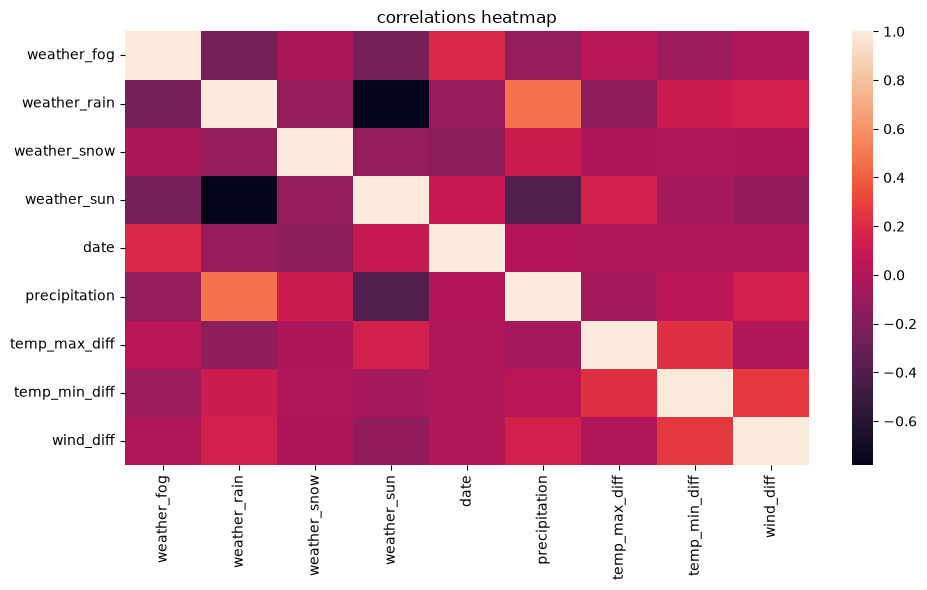

In [87]:
plt.figure(figsize=(10, 6))
sns.heatmap(data_diff.corr())
plt.title("correlations heatmap")
plt.tight_layout()
plt.show()

### converting data into year, month and days

In [88]:
data_diff['year'] = data_diff['date'].dt.year
data_diff['month'] = data_diff['date'].dt.month
data_diff['day'] = data_diff['date'].dt.day
data_diff.drop(columns=['date'], inplace=True)

## ivar and dvar

In [89]:
endog = data_diff['precipitation']
exogs = data_diff[['weather_fog', 'weather_rain', 'weather_snow', 'weather_sun',
       'temp_max_diff', 'temp_min_diff', 'wind_diff', 'year', 'month', 'day']]

In [90]:
print("--- EXOG DATATYPES ---")
print(exogs.dtypes)

print("\n--- ENDOG DATATYPE ---")
print(endog.dtype)

--- EXOG DATATYPES ---
weather_fog      object
weather_rain     object
weather_snow     object
weather_sun      object
temp_max_diff    object
temp_min_diff    object
wind_diff        object
year              int32
month             int32
day               int32
dtype: object

--- ENDOG DATATYPE ---
object


In [91]:
# 1. Convert all columns in exogs to numeric, forcing any corrupted/string values to NaN
exogs_clean = exogs.apply(pd.to_numeric, errors='coerce')

# 2. Also ensure your endog ('precipitation') is numeric
endog_clean = pd.to_numeric(endog, errors='coerce')

# 3. Drop any resulting NaNs to ensure data alignment and cleanliness
model_data = pd.concat([endog_clean, exogs_clean], axis=1).dropna()

endog_final = model_data.iloc[:, 0]
exogs_final = model_data.iloc[:, 1:]

## Applying ARIMA

In [92]:
from statsmodels.tsa.arima.model import ARIMA
p,d,q = 1,1,1
model = ARIMA(endog = endog_final, exog=exogs_final, order=(p,d,q))
model_fit = model.fit()

#summary
print(model_fit.summary())

/home/anuj/anaconda3/lib/python3.14/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:          precipitation   No. Observations:                 1460
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -4612.499
Date:                Sat, 31 Oct 2026   AIC                           9250.998
Time:                        11:13:02   BIC                           9319.710
Sample:                             0   HQIC                          9276.631
                               - 1460                                         
Covariance Type:                  opg                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
weather_fog      -1.3548      3.496     -0.387      0.698      -8.207       5.498
weather_rain      5.2008      3.601      1.444      0.149      -1.858      12.259
weather_snow      7.4462      3.756     

#### again trying ot train model 

In [93]:
endog = data_diff['precipitation']
exogs = data_diff[[ 'weather_rain', 'weather_snow',
        'temp_min_diff', 'wind_diff']]
exogs_clean = exogs.apply(pd.to_numeric, errors='coerce')

# 2. Also ensure your endog ('precipitation') is numeric
endog_clean = pd.to_numeric(endog, errors='coerce')

# 3. Drop any resulting NaNs to ensure data alignment and cleanliness
model_data = pd.concat([endog_clean, exogs_clean], axis=1).dropna()

endog_final = model_data.iloc[:, 0]
exogs_final = model_data.iloc[:, 1:]
exogs_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 1 to 1460
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   weather_rain   1460 non-null   float64
 1   weather_snow   1460 non-null   float64
 2   temp_min_diff  1460 non-null   float64
 3   wind_diff      1460 non-null   float64
dtypes: float64(4)
memory usage: 45.8 KB


In [94]:
from sklearn.preprocessing import  StandardScaler, MinMaxScaler
trf3 = ColumnTransformer([
    ('scaler', MinMaxScaler(), ['temp_min_diff', 'wind_diff'])
], remainder='passthrough')

# 3. Fit and transform the feature matrix
transformed_exog = trf3.fit_transform(exogs_final)

# 4. Extract and clean column names
raw_names = trf3.get_feature_names_out()
clean_names = [
    col.replace('scaler__', '').replace('remainder__', '') 
    for col in raw_names
]

# 5. Reconstruct the clean, scaled exog DataFrame preserving the index
exog_scaled = pd.DataFrame(transformed_exog, columns=clean_names, index=exogs_final.index)

# 6. Refit the ARIMAX model
p, d, q = 1, 1, 1
model = ARIMA(endog=endog_final, exog=exog_scaled, order=(p, d, q))
model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:          precipitation   No. Observations:                 1460
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -4613.766
Date:                Sat, 31 Oct 2026   AIC                           9241.531
Time:                        11:13:05   BIC                           9278.530
Sample:                             0   HQIC                          9255.334
                               - 1460                                         
Covariance Type:                  opg                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
temp_min_diff    -1.7630      1.037     -1.700      0.089      -3.795       0.269
wind_diff         4.7738      1.126      4.241      0.000       2.567       6.980
weather_rain      5.9964      0.465     

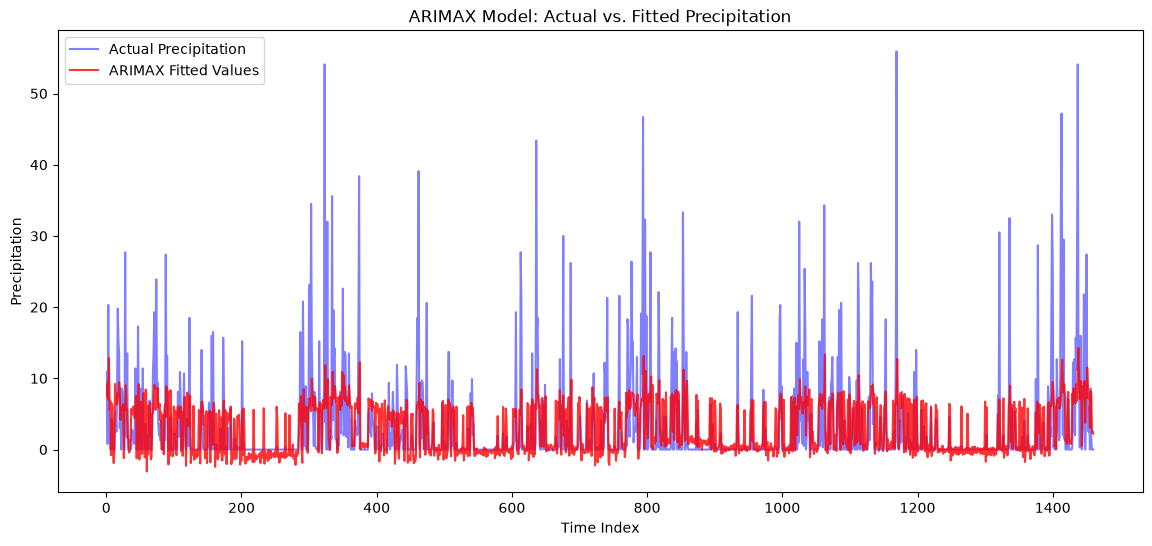

In [95]:
plt.figure(figsize=(14, 6))
plt.plot(endog_final.index, endog_final, label='Actual Precipitation', color='blue', alpha=0.5)
plt.plot(endog_final.index, model_fit.fittedvalues, label='ARIMAX Fitted Values', color='red', alpha=0.8)

plt.title('ARIMAX Model: Actual vs. Fitted Precipitation')
plt.xlabel('Time Index')
plt.ylabel('Precipitation')
plt.legend()
plt.show()

## Other Machine learning algos

### Logistic regression with netwon's method

In [96]:
data.head()

,precipitation,temp_max,temp_min,wind,weather
date,,,,,
2012-01-01,0.0,12.8,5.0,4.7,drizzle
2012-01-02,10.9,10.6,2.8,4.5,rain
2012-01-03,0.8,11.7,7.2,2.3,rain
2012-01-04,20.3,12.2,5.6,4.7,rain
2012-01-05,1.3,8.9,2.8,6.1,rain


In [97]:
# to_datetime

#defined function 
def to_datetime(X):
    return pd.DataFrame(pd.to_datetime(X.iloc[:,0]))

trf = ColumnTransformer([
    ('datetime-data',FunctionTransformer(to_datetime), [0])
], remainder='passthrough')

#fit transfrom
transformed_data = trf.fit_transform(df)
data = pd.DataFrame(transformed_data, columns=df.columns)
data.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


In [98]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
encoded_weather = pd.Series(encoder.fit_transform(df['weather']), name = 'weather_encoded')
data = pd.concat([df, encoded_weather], axis = 1)
data.head()

,date,precipitation,temp_max,temp_min,wind,weather,weather_encoded
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle,0
1,2012-01-02,10.9,10.6,2.8,4.5,rain,2
2,2012-01-03,0.8,11.7,7.2,2.3,rain,2
3,2012-01-04,20.3,12.2,5.6,4.7,rain,2
4,2012-01-05,1.3,8.9,2.8,6.1,rain,2


### precipitation based on weather

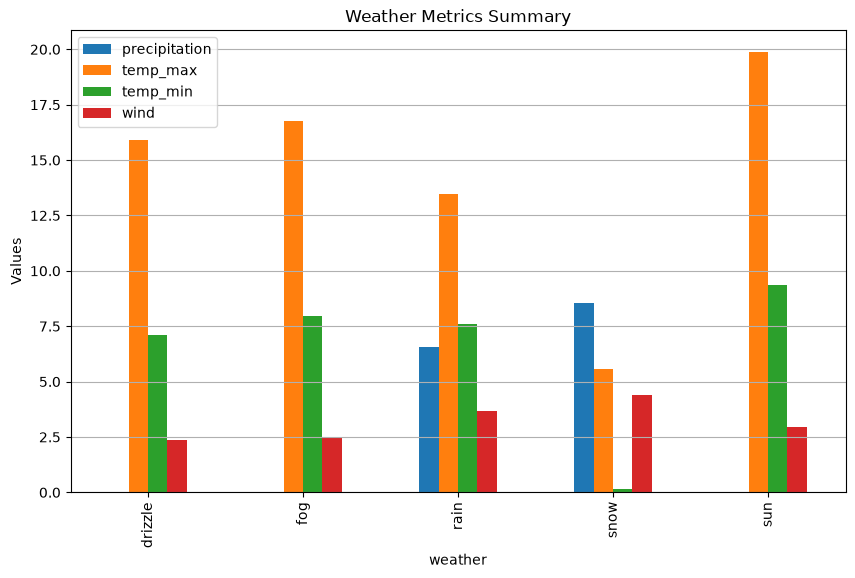

In [99]:
plt.figure(figsize=(10, 6))

presentation = data.groupby('weather')[['precipitation', 'temp_max', 'temp_min', 'wind']].agg(
    ['mean', 'max', 'min']
)

presentation.xs('mean', axis=1, level=1).plot(kind='bar', ax=plt.gca())

plt.title('Weather Metrics Summary')
plt.ylabel('Values')
plt.grid(visible='both', axis = 'y')
plt.show()

In [100]:
# 1. Convert the column to datetime first
data['date'] = pd.to_datetime(data['date'])


data['year'] = data['date'].dt.year
data['month'] = data['date'].dt.month
data['day'] = data['date'].dt.day
data['week_day'] = data['date'].dt.day_name()

data.head()

,date,precipitation,temp_max,temp_min,wind,weather,weather_encoded,year,month,day,week_day
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle,0,2012,1,1,Sunday
1,2012-01-02,10.9,10.6,2.8,4.5,rain,2,2012,1,2,Monday
2,2012-01-03,0.8,11.7,7.2,2.3,rain,2,2012,1,3,Tuesday
3,2012-01-04,20.3,12.2,5.6,4.7,rain,2,2012,1,4,Wednesday
4,2012-01-05,1.3,8.9,2.8,6.1,rain,2,2012,1,5,Thursday


#### year-trend

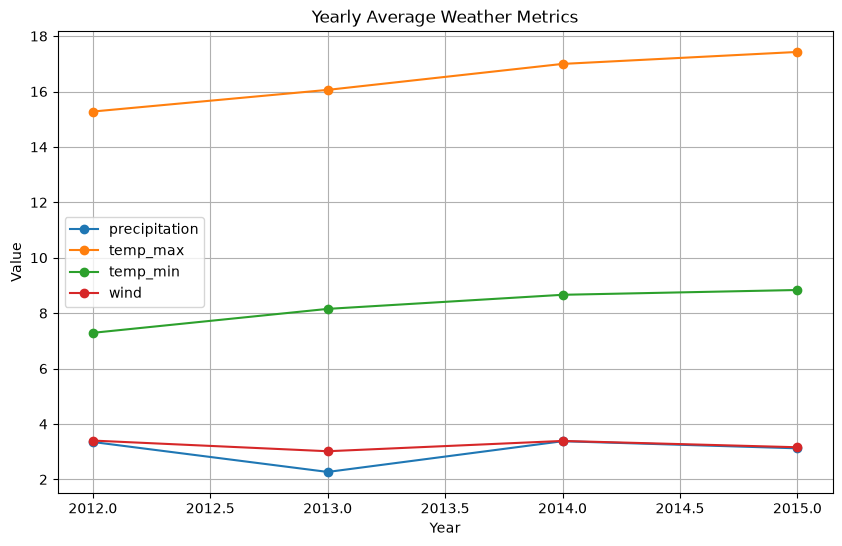

In [101]:

plt.figure(figsize=(10, 6))

# 1. Group by year and calculate the mean
yearly_data = data.groupby('year')[['precipitation', 'temp_max', 'temp_min', 'wind']].mean()

# 2. Plot directly using pandas (passing plt.gca() to use your figure size)
yearly_data.plot(ax=plt.gca(), marker='o')

plt.title('Yearly Average Weather Metrics')
plt.xlabel('Year')
plt.ylabel('Value')
plt.grid(True)
plt.show()

#### KDE plot

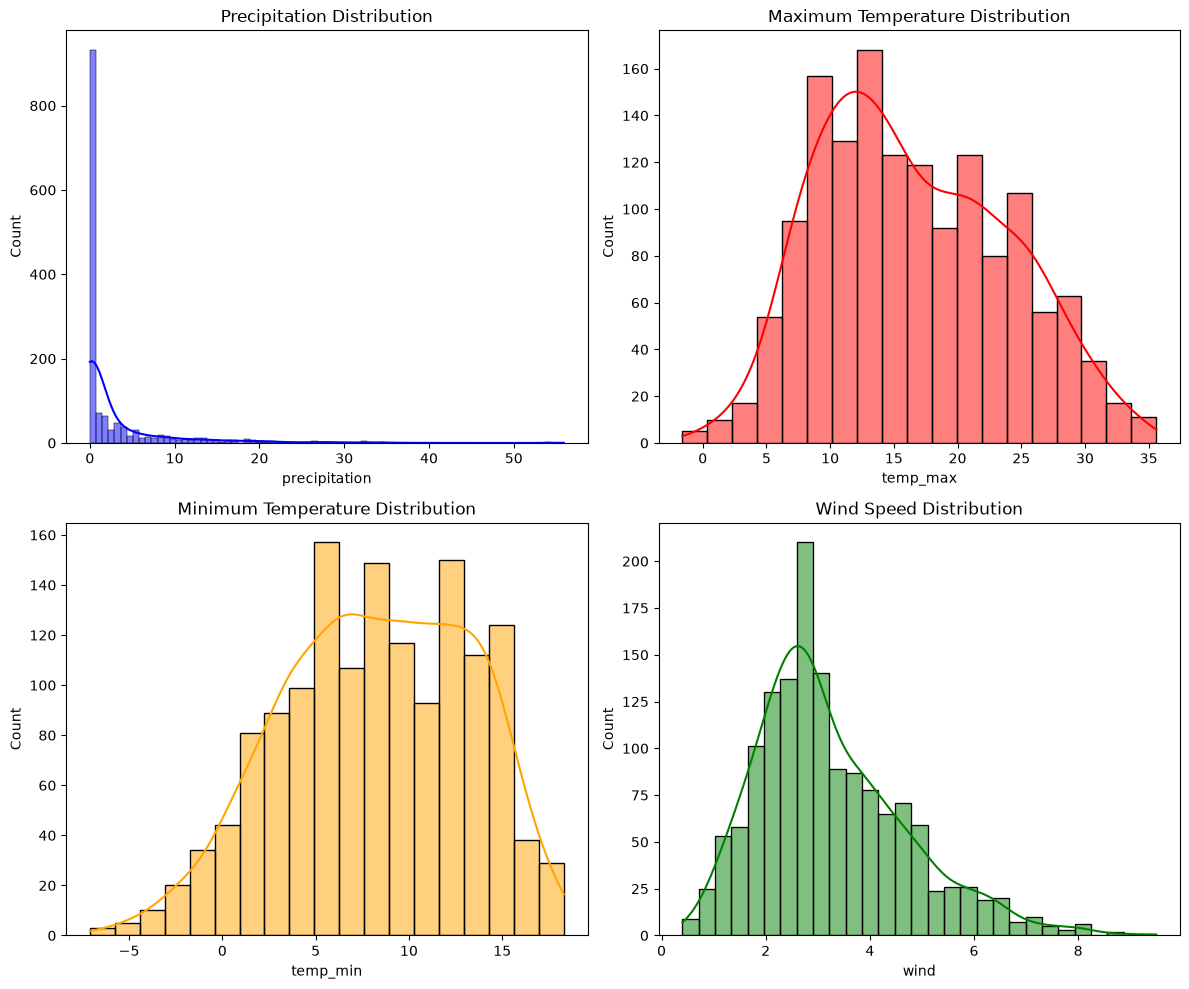

In [102]:

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Plot each variable in its own subplot
sns.histplot(data['precipitation'], kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Precipitation Distribution')

sns.histplot(data['temp_max'], kde=True, ax=axes[0, 1], color='red')
axes[0, 1].set_title('Maximum Temperature Distribution')

sns.histplot(data['temp_min'], kde=True, ax=axes[1, 0], color='orange')
axes[1, 0].set_title('Minimum Temperature Distribution')

sns.histplot(data['wind'], kde=True, ax=axes[1, 1], color='green')
axes[1, 1].set_title('Wind Speed Distribution')

plt.tight_layout()
plt.show()

### kurtosis

In [103]:
from scipy.stats import kurtosis
kurtosis(data[['precipitation','temp_max', 'temp_min', 'wind']])

array([15.46500349, -0.69221027, -0.60262324,  0.79710803])

### appying power transfomer yeo-johnson

In [104]:
from sklearn.preprocessing import PowerTransformer

# Choose the three columns you want to transform
transform_cols = ['precipitation', 'temp_max', 'temp_min', 'wind']

# Set up the ColumnTransformer
power_transfrom = ColumnTransformer(
    transformers=[
        ('power_trans', PowerTransformer(method='yeo-johnson'), transform_cols)
    ],
    remainder='passthrough'  
)

transformed_power = pd.DataFrame(
    PowerTransformer(method='yeo-johnson').fit_transform(data[transform_cols]),
    columns=[f'{col}_pow' for col in transform_cols],  # Adds '_pow' suffix
    index=data.index
)

# Concatenate safely without duplicate name clashes
data = pd.concat([data, transformed_power], axis=1)
data.head()


,date,precipitation,temp_max,temp_min,wind,weather,weather_encoded,year,month,day,week_day,precipitation_pow,temp_max_pow,temp_min_pow,wind_pow
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle,0,2012,1,1,Sunday,-0.792227,-0.432216,-0.661059,1.055553
1,2012-01-02,10.9,10.6,2.8,4.5,rain,2,2012,1,2,Monday,1.594572,-0.757983,-1.092225,0.947659
2,2012-01-03,0.8,11.7,7.2,2.3,rain,2,2012,1,3,Tuesday,0.371270,-0.592814,-0.222862,-0.590536
3,2012-01-04,20.3,12.2,5.6,4.7,rain,2,2012,1,4,Wednesday,1.689481,-0.519279,-0.542147,1.055553
4,2012-01-05,1.3,8.9,2.8,6.1,rain,2,2012,1,5,Thursday,0.686166,-1.023638,-1.092225,1.719964


In [105]:
cols = ['date', 'precipitation', 'temp_max', 'temp_min', 'wind']

# Pass 'cols' directly without wrapping it in extra brackets
data.drop(columns=cols, inplace=True)

data.head()

,weather,weather_encoded,year,month,day,week_day,precipitation_pow,temp_max_pow,temp_min_pow,wind_pow
0,drizzle,0,2012,1,1,Sunday,-0.792227,-0.432216,-0.661059,1.055553
1,rain,2,2012,1,2,Monday,1.594572,-0.757983,-1.092225,0.947659
2,rain,2,2012,1,3,Tuesday,0.371270,-0.592814,-0.222862,-0.590536
3,rain,2,2012,1,4,Wednesday,1.689481,-0.519279,-0.542147,1.055553
4,rain,2,2012,1,5,Thursday,0.686166,-1.023638,-1.092225,1.719964


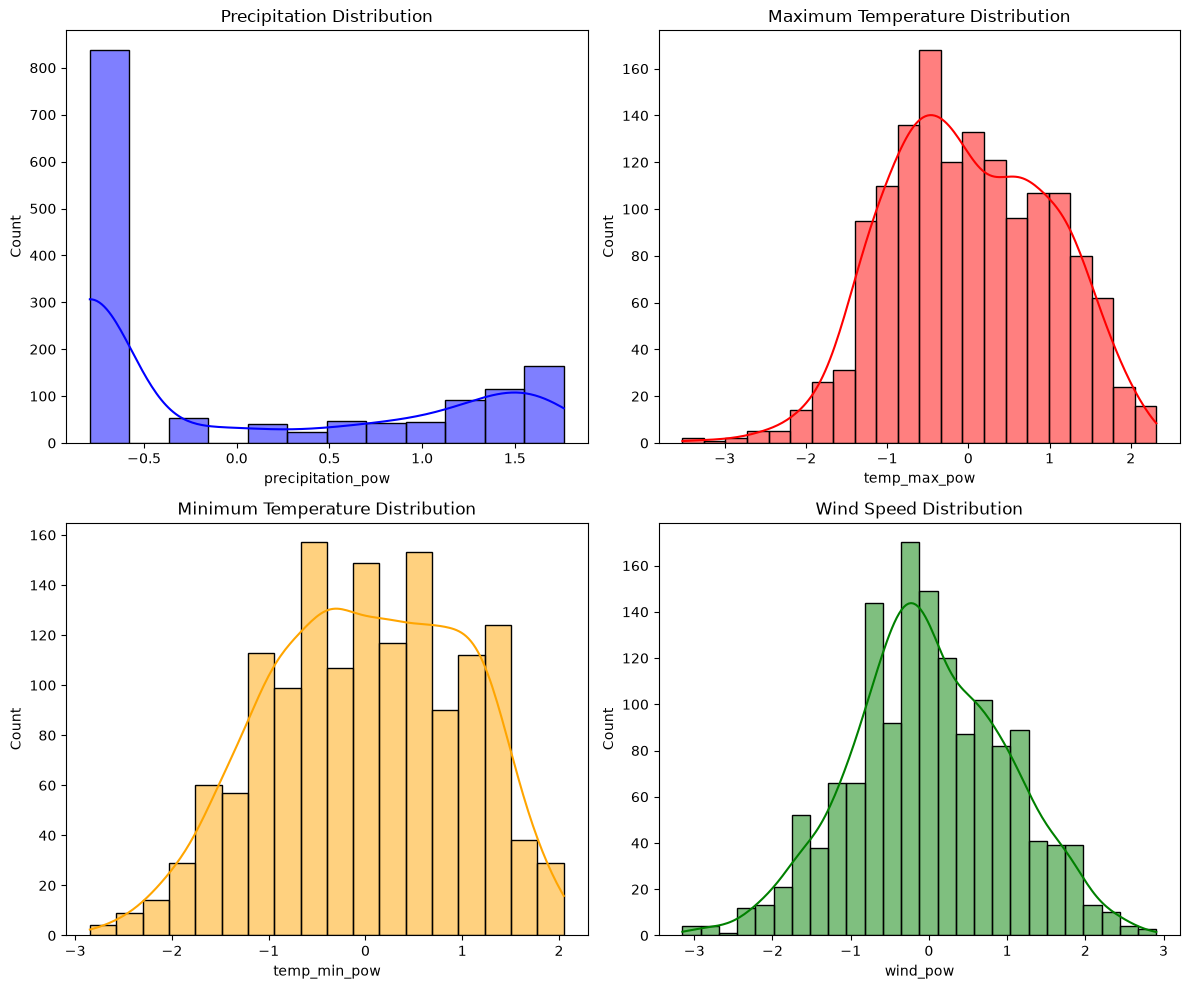

In [106]:
cols = [ 'precipitation_pow', 'temp_max_pow', 'temp_min_pow', 'wind_pow']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Plot each variable in its own subplot
sns.histplot(data['precipitation_pow'], kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Precipitation Distribution')

sns.histplot(data['temp_max_pow'], kde=True, ax=axes[0, 1], color='red')
axes[0, 1].set_title('Maximum Temperature Distribution')

sns.histplot(data['temp_min_pow'], kde=True, ax=axes[1, 0], color='orange')
axes[1, 0].set_title('Minimum Temperature Distribution')

sns.histplot(data['wind_pow'], kde=True, ax=axes[1, 1], color='green')
axes[1, 1].set_title('Wind Speed Distribution')

plt.tight_layout()
plt.show()

### One hot enconding for year

In [107]:
data.drop(columns = ['weather', 'day', 'week_day'], inplace=True)

In [108]:
# year
trf_year = ColumnTransformer([
    ('transformed_year', OneHotEncoder(sparse_output=False, drop='first'), ['year'])
], remainder='passthrough')

# 2. Fit and transform the data
transformed_array = trf_year.fit_transform(data)

# 3. Retrieve the generated feature names for the one-hot encoded year columns
# (Works with scikit-learn 1.2+)
encoded_year_cols = trf_year.named_transformers_['transformed_year'].get_feature_names_out(['year'])

# 4. Get the remaining column names (all columns except 'year')
remaining_cols = [col for col in data.columns if col != 'year']

# 5. Combine the new feature names in the exact order output by ColumnTransformer
all_column_names = list(encoded_year_cols) + remaining_cols

# 6. Reconstruct the final concatenated DataFrame
data = pd.DataFrame(transformed_array, columns=all_column_names, index=data.index)
print(data.head())

   year_2013  year_2014  year_2015  weather_encoded  month  precipitation_pow  \
0        0.0        0.0        0.0              0.0    1.0          -0.792227   
1        0.0        0.0        0.0              2.0    1.0           1.594572   
2        0.0        0.0        0.0              2.0    1.0           0.371270   
3        0.0        0.0        0.0              2.0    1.0           1.689481   
4        0.0        0.0        0.0              2.0    1.0           0.686166   

   temp_max_pow  temp_min_pow  wind_pow  
0     -0.432216     -0.661059  1.055553  
1     -0.757983     -1.092225  0.947659  
2     -0.592814     -0.222862 -0.590536  
3     -0.519279     -0.542147  1.055553  
4     -1.023638     -1.092225  1.719964  


#### Month endoer is Sine
* since, months hold equal weightage

In [112]:
# 1. Define the robust sine transformation function (handles pandas DataFrames safely)
def sine_transformed(X):
    # Check if X is a pandas object (DataFrame or Series) and use .iloc
    if hasattr(X, 'iloc'):
        col = X.iloc[:, 0]
    else:
        col = X[:, 0]  # Fallback for numpy arrays
    
    # Compute sine and reshape to 2D
    return np.sin((2 * np.pi * col) / 12).to_numpy().reshape(-1, 1)

# 2. Define your ColumnTransformer
trf_month = ColumnTransformer([
    ('month_transformed', FunctionTransformer(sine_transformed), ['month'])
], remainder='passthrough')

# 3. Fit and transform the dataset
transformed_array = trf_month.fit_transform(data)

# 4. Set up column names (ColumnTransformer puts transformed columns first)
transformed_cols = ['month_sine']
remaining_cols = [col for col in data.columns if col != 'month']
all_column_names = transformed_cols + remaining_cols

# 5. Reconstruct the final concatenated DataFrame
data_transformed = pd.DataFrame(
    transformed_array, 
    columns=all_column_names, 
    index=data.index
)

# Preview the result
print(data_transformed.head())

   month_sine  year_2013  year_2014  year_2015  weather_encoded  \
0         0.5        0.0        0.0        0.0              0.0   
1         0.5        0.0        0.0        0.0              2.0   
2         0.5        0.0        0.0        0.0              2.0   
3         0.5        0.0        0.0        0.0              2.0   
4         0.5        0.0        0.0        0.0              2.0   

   precipitation_pow  temp_max_pow  temp_min_pow  wind_pow  
0          -0.792227     -0.432216     -0.661059  1.055553  
1           1.594572     -0.757983     -1.092225  0.947659  
2           0.371270     -0.592814     -0.222862 -0.590536  
3           1.689481     -0.519279     -0.542147  1.055553  
4           0.686166     -1.023638     -1.092225  1.719964  


## depended and independent variable


In [113]:
X = data_transformed.drop(columns=['weather_encoded'])
y = data_transformed['weather_encoded']

,month_sine,year_2013,year_2014,year_2015,precipitation_pow,temp_max_pow,temp_min_pow,wind_pow
0,0.5,0.0,0.0,0.0,-0.792227,-0.432216,-0.661059,1.055553
1,0.5,0.0,0.0,0.0,1.594572,-0.757983,-1.092225,0.947659
2,0.5,0.0,0.0,0.0,0.371270,-0.592814,-0.222862,-0.590536
3,0.5,0.0,0.0,0.0,1.689481,-0.519279,-0.542147,1.055553
4,0.5,0.0,0.0,0.0,0.686166,-1.023638,-1.092225,1.719964


### Robust Scaler

In [118]:
from sklearn.preprocessing import RobustScaler


scaled_cols = ['precipitation_pow', 'temp_max_pow', 'temp_min_pow', 'wind_pow']

# 2. Set up the ColumnTransformer
robust = ColumnTransformer([
    ('robust-scaler', RobustScaler(), scaled_cols)
], remainder='passthrough')

# 3. Fit and transform your independent variables (X)
robust_data = robust.fit_transform(X)

# 4. Get the list of remaining columns that passed through untouched
remaining_cols = [col for col in X.columns if col not in scaled_cols]

# 5. ColumnTransformer always puts the transformed/scaled columns FIRST, 
# followed by the remainder columns. We set the column names to match this order:
transformer_col_order = scaled_cols + remaining_cols

# 6. Convert the resulting numpy array back into a temporary pandas DataFrame
X_temp = pd.DataFrame(robust_data, columns=transformer_col_order, index=X.index)

# 7. Reorder the columns back to match your original X sequence and overwrite X
X = X_temp[X.columns]

# Preview the final updated X DataFrame
print(X.head())

   month_sine  year_2013  year_2014  year_2015  precipitation_pow  \
0         0.5        0.0        0.0        0.0           0.000000   
1         0.5        0.0        0.0        0.0           1.240273   
2         0.5        0.0        0.0        0.0           0.604598   
3         0.5        0.0        0.0        0.0           1.289591   
4         0.5        0.0        0.0        0.0           0.768230   

   temp_max_pow  temp_min_pow  wind_pow  
0     -0.250249     -0.419929  0.795220  
1     -0.458629     -0.694548  0.714875  
2     -0.352977     -0.140831 -0.430571  
3     -0.305940     -0.344191  0.795220  
4     -0.628559     -0.694548  1.289986  


### checing outliers


<Axes: >

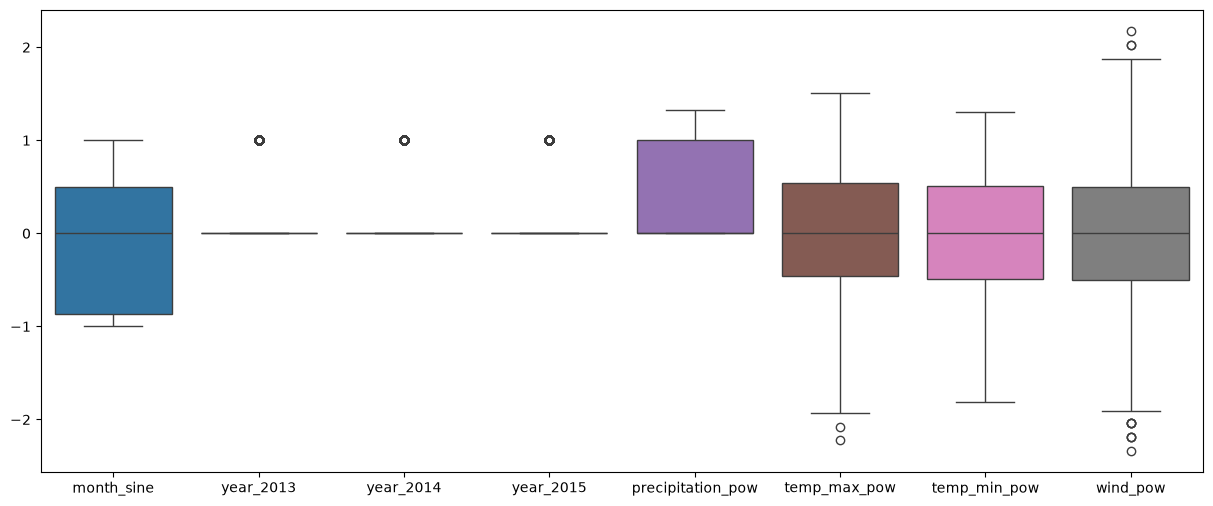

In [121]:
plt.figure(figsize=(15,6))
sns.boxplot(X)

## training model called Logistic regression with newton

In [124]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# 1. Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Initialize the Logistic Regression model with 'newton-cg' and correct parameter 'max_iter'
clf = LogisticRegression(solver='newton-cg', max_iter=100)

# 3. Train the model
clf.fit(X_train, y_train)

# 4. Make predictions on both train and test sets
y_train_pred = clf.predict(X_train)
y_test_pred = clf.predict(X_test)

# 5. Evaluate model performance
print(
    f"Training Accuracy: {accuracy_score(y_train, y_train_pred) * 100:.2f}%"
)
print(f"Testing Accuracy:  {accuracy_score(y_test, y_test_pred) * 100:.2f}%\n")

print("--- Classification Report (Test Data) ---")
print(classification_report(y_test, y_test_pred))

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_test_pred))

Training Accuracy: 85.19%
Testing Accuracy:  83.62%

--- Classification Report (Test Data) ---
              precision    recall  f1-score   support

         0.0       0.00      0.00      0.00         9
         1.0       0.50      0.04      0.07        25
         2.0       0.94      0.94      0.94       120
         3.0       1.00      0.12      0.22         8
         4.0       0.76      0.99      0.86       131

    accuracy                           0.84       293
   macro avg       0.64      0.42      0.42       293
weighted avg       0.80      0.84      0.78       293

--- Confusion Matrix ---
[[  0   0   0   0   9]
 [  0   1   0   0  24]
 [  0   0 113   0   7]
 [  0   0   7   1   0]
 [  0   1   0   0 130]]


/home/anuj/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/anuj/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/anuj/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### class balanced

In [123]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# 1. Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Initialize the Logistic Regression model with 'newton-cg' and correct parameter 'max_iter'
clf = LogisticRegression(solver='newton-cg', max_iter=100, class_weight='balanced')

# 3. Train the model
clf.fit(X_train, y_train)

# 4. Make predictions on both train and test sets
y_train_pred = clf.predict(X_train)
y_test_pred = clf.predict(X_test)

# 5. Evaluate model performance
print(
    f"Training Accuracy: {accuracy_score(y_train, y_train_pred) * 100:.2f}%"
)
print(f"Testing Accuracy:  {accuracy_score(y_test, y_test_pred) * 100:.2f}%\n")

print("--- Classification Report (Test Data) ---")
print(classification_report(y_test, y_test_pred))

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_test_pred))

Training Accuracy: 64.21%
Testing Accuracy:  67.92%

--- Classification Report (Test Data) ---
              precision    recall  f1-score   support

         0.0       0.16      0.78      0.26         9
         1.0       0.29      0.60      0.39        25
         2.0       1.00      0.82      0.90       120
         3.0       0.42      1.00      0.59         8
         4.0       0.88      0.54      0.67       131

    accuracy                           0.68       293
   macro avg       0.55      0.75      0.56       293
weighted avg       0.84      0.68      0.73       293

--- Confusion Matrix ---
[[ 7  0  0  0  2]
 [ 4 15  0  0  6]
 [ 8  1 98 11  2]
 [ 0  0  0  8  0]
 [25 35  0  0 71]]


### custome class weight

In [126]:
# 2. Define custom class weights to fine-tune the trade-off
# You can tweak these numbers up or down based on your results:
custom_weights = {
    0.0: 3.0,  
    1.0: 2.0,  
    2.0: 1.0,  
    3.0: 4.0,  
    4.0: 1.0  }
# 3. Initialize the Logistic Regression model with custom weights
clf = LogisticRegression(solver='newton-cg', max_iter=100, class_weight=custom_weights)

# 4. Train the model
clf.fit(X_train, y_train)

# 5. Make predictions
y_train_pred = clf.predict(X_train)
y_test_pred = clf.predict(X_test)

# 6. Evaluate performance
print(f"Training Accuracy: {accuracy_score(y_train, y_train_pred) * 100:.2f}%")
print(f"Testing Accuracy:  {accuracy_score(y_test, y_test_pred) * 100:.2f}%\n")

print("--- Classification Report (Test Data) ---")
print(classification_report(y_test, y_test_pred))

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_test_pred))

Training Accuracy: 84.59%
Testing Accuracy:  84.64%

--- Classification Report (Test Data) ---
              precision    recall  f1-score   support

         0.0       0.33      0.11      0.17         9
         1.0       0.70      0.28      0.40        25
         2.0       0.97      0.90      0.94       120
         3.0       0.56      0.62      0.59         8
         4.0       0.79      0.97      0.87       131

    accuracy                           0.85       293
   macro avg       0.67      0.58      0.59       293
weighted avg       0.84      0.85      0.83       293

--- Confusion Matrix ---
[[  1   0   0   0   8]
 [  0   7   0   0  18]
 [  1   0 108   4   7]
 [  0   0   3   5   0]
 [  1   3   0   0 127]]
